### Import libraries

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [2]:
# Define dataset paths

DATASET_DIR = Path("../dataset")

TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "validation"
TEST_DIR = DATASET_DIR / "test"

print("Dataset path:", DATASET_DIR.resolve())

Dataset path: D:\deepfake\dataset


In [3]:
# Count Images in each split and category

def count_images(folder):
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    
    return sum(
        1 for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in extensions
    )


for split_name, split_dir in {
    "Train": TRAIN_DIR,
    "Validation": VAL_DIR,
    "Test": TEST_DIR
}.items():

    real_count = count_images(split_dir / "real")
    fake_count = count_images(split_dir / "fake")

    print(f"{split_name}:")
    print(f"  Real: {real_count}")
    print(f"  Fake: {fake_count}")
    print(f"  Total: {real_count + fake_count}")
    print()

Train:
  Real: 756
  Fake: 672
  Total: 1428

Validation:
  Real: 162
  Fake: 144
  Total: 306

Test:
  Real: 163
  Fake: 144
  Total: 307



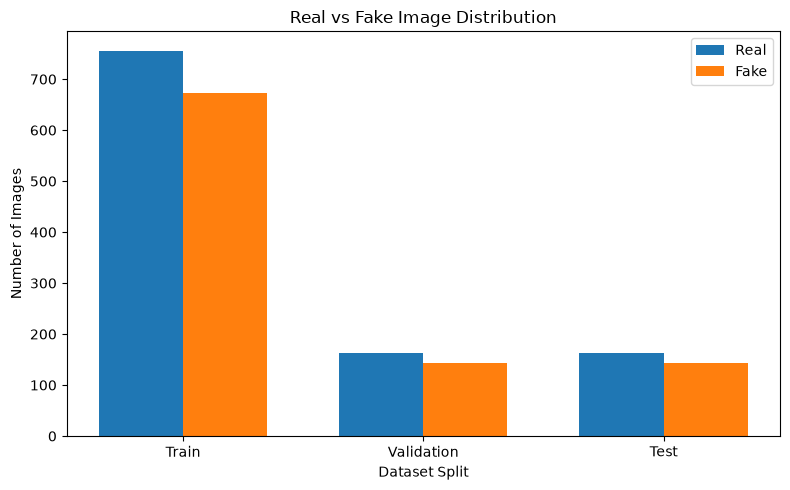

In [4]:
# Visualize class distribution

splits = ["Train", "Validation", "Test"]

real_counts = [756, 162, 163]
fake_counts = [672, 144, 144]

x = np.arange(len(splits))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, real_counts, width, label="Real")
plt.bar(x + width/2, fake_counts, width, label="Fake")

plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.title("Real vs Fake Image Distribution")

plt.xticks(x, splits)
plt.legend()

plt.tight_layout()
plt.show()

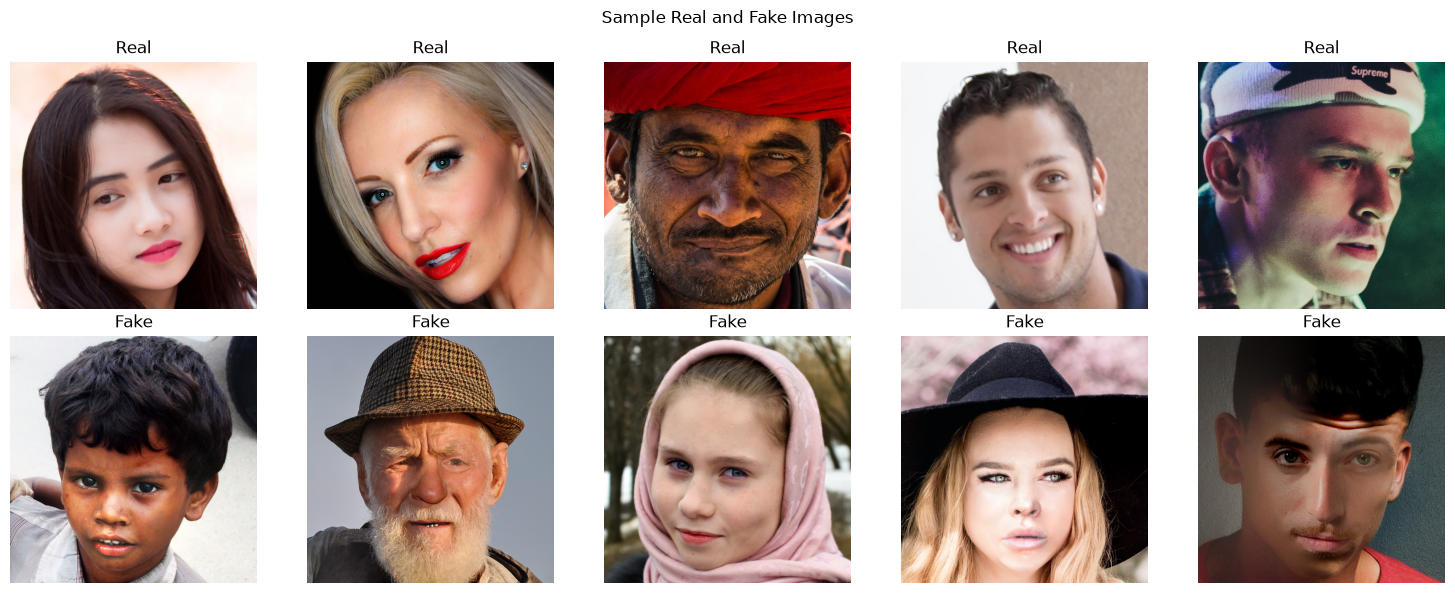

In [5]:
# Display sample images

import random

def get_images(folder, n=5):
    images = [
        file for file in folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
    return random.sample(images, min(n, len(images)))


real_images = get_images(TRAIN_DIR / "real", 5)
fake_images = get_images(TRAIN_DIR / "fake", 5)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, image_path in enumerate(real_images):
    image = Image.open(image_path).convert("RGB")
    axes[0, i].imshow(image)
    axes[0, i].set_title("Real")
    axes[0, i].axis("off")

for i, image_path in enumerate(fake_images):
    image = Image.open(image_path).convert("RGB")
    axes[1, i].imshow(image)
    axes[1, i].set_title("Fake")
    axes[1, i].axis("off")

plt.suptitle("Sample Real and Fake Images")
plt.tight_layout()
plt.show()

In [6]:
# Check image dimensions

def get_image_sizes(folder):
    sizes = []

    for image_path in folder.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            try:
                with Image.open(image_path) as img:
                    sizes.append(img.size)
            except Exception:
                pass

    return sizes


real_sizes = get_image_sizes(TRAIN_DIR / "real")
fake_sizes = get_image_sizes(TRAIN_DIR / "fake")

print("Real images:")
print("Number of images:", len(real_sizes))
print("Unique dimensions:", len(set(real_sizes)))
print("Most common dimensions:")
print(pd.Series(real_sizes).value_counts().head(10))

print("\nFake images:")
print("Number of images:", len(fake_sizes))
print("Unique dimensions:", len(set(fake_sizes)))
print("Most common dimensions:")
print(pd.Series(fake_sizes).value_counts().head(10))

Real images:
Number of images: 756
Unique dimensions: 1
Most common dimensions:
(600, 600)    756
Name: count, dtype: int64

Fake images:
Number of images: 672
Unique dimensions: 1
Most common dimensions:
(600, 600)    672
Name: count, dtype: int64


In [7]:
# Check for corrupted images

def check_corrupted_images(folder):
    corrupted = []

    for image_path in folder.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            try:
                with Image.open(image_path) as img:
                    img.verify()
            except Exception:
                corrupted.append(str(image_path))

    return corrupted


for split_name, split_dir in {
    "Train": TRAIN_DIR,
    "Validation": VAL_DIR,
    "Test": TEST_DIR
}.items():

    corrupted = check_corrupted_images(split_dir)

    print(f"{split_name}: {len(corrupted)} corrupted images")

    if corrupted:
        print("Examples:")
        for path in corrupted[:5]:
            print(path)

Train: 0 corrupted images
Validation: 0 corrupted images
Test: 0 corrupted images
